## Cleaning the daily variation of temperatures

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### 0- Opening and reading the data

In [2]:
df = pd.read_csv("data/data2_dates_corrigees.csv", encoding="utf-8-sig", sep=";")
df.columns = df.columns.str.strip()

# Read the DateTime column as datetime
df["DateTime"] = pd.to_datetime(
    df["DateTime"],
    format="%d.%m.%Y %H:%M"
)

df

,ID,DateTime,Vbatt,T_SHT,H_SHT,T_BMP,P_BMP,Q_SFM,V_SFM,T_SFM
0,1,2026-04-11 15:30:00,4.18,5.675,74.6,5.33,920.25,5.891667,1.188908,5.425
1,2,2026-04-11 15:45:00,4.18,5.520,71.5,5.09,920.27,5.791666,1.174219,5.465
2,3,2026-04-11 16:00:00,4.18,5.408,67.9,5.02,920.26,5.391667,1.115192,5.485
3,4,2026-04-11 16:15:00,4.18,5.464,65.0,4.98,920.30,5.258333,1.095403,5.405
4,5,2026-04-11 16:30:00,4.18,5.338,64.2,4.98,920.44,6.883333,1.332115,5.390
...,...,...,...,...,...,...,...,...,...,...
10149,10150,2026-07-25 10:38:00,3.44,5.256,94.6,4.92,923.86,7.416666,1.407509,5.200
10150,10151,2026-07-25 10:54:00,3.44,5.312,94.7,4.91,923.85,7.783333,1.458913,5.135
10151,10152,2026-07-25 11:08:00,3.44,5.352,94.7,4.92,923.84,7.625000,1.436750,5.130
10152,10153,2026-07-25 11:23:00,3.44,5.312,94.6,4.91,923.85,0.075000,0.069239,5.305


The goal is to isolate the daily variation of the `V_SFM` parameter

In [3]:
# Mean of V_SFM
mean_V_SFM = df["V_SFM"].mean()

print(f"Mean of V_SFM: {mean_V_SFM}")

# Median of V_SFM
median_V_SFM = df["V_SFM"].median()

print(f"Median of V_SFM: {median_V_SFM}")

Mean of V_SFM: 1.367646345272799
Median of V_SFM: 1.3969573


### 1- Cleaning the data

#### Formating the hour and date

We separate the day and the hour

In [4]:
df["day"] = df["DateTime"].dt.date
df["hour"] = df["DateTime"].dt.strftime("%H:%M")

df.head()

,ID,DateTime,Vbatt,T_SHT,H_SHT,T_BMP,P_BMP,Q_SFM,V_SFM,T_SFM,day,hour
0,1,2026-04-11 15:30:00,4.18,5.675,74.6,5.33,920.25,5.891667,1.188908,5.425,2026-04-11,15:30
1,2,2026-04-11 15:45:00,4.18,5.520,71.5,5.09,920.27,5.791666,1.174219,5.465,2026-04-11,15:45
2,3,2026-04-11 16:00:00,4.18,5.408,67.9,5.02,920.26,5.391667,1.115192,5.485,2026-04-11,16:00
3,4,2026-04-11 16:15:00,4.18,5.464,65.0,4.98,920.30,5.258333,1.095403,5.405,2026-04-11,16:15
4,5,2026-04-11 16:30:00,4.18,5.338,64.2,4.98,920.44,6.883333,1.332115,5.390,2026-04-11,16:30


In [5]:
df["hour"].value_counts()

hour
19:30    26
07:30    25
20:24    18
07:03    18
19:57    18
         ..
10:30     7
12:00     7
12:45     7
14:15     7
15:00     7
Name: count, Length: 1084, dtype: int64

We notice that the times of measure have slightly slided off during the sampling period. Because some hours are less represented than other we adjust all times to their 15 min intervall. This give us statistical significance and regularity in the sampling.

In [6]:
df["hour_15min_interval"] = (
    df["DateTime"].dt.floor("15min").dt.strftime("%H:%M")
)

df["hour_15min_interval"].value_counts()

hour_15min_interval
16:15    114
16:45    114
17:15    114
19:00    114
19:30    114
        ... 
05:00     96
07:15     96
09:45     96
12:00     95
14:15     95
Name: count, Length: 96, dtype: int64

In [7]:
df[["day", "hour_15min_interval"]].value_counts()

day         hour_15min_interval
2026-04-19  04:15                  2
            04:45                  2
            05:15                  2
2026-04-20  07:00                  2
            07:30                  2
                                  ..
2026-07-25  10:30                  1
            10:45                  1
            11:00                  1
            11:15                  1
            11:30                  1
Name: count, Length: 9958, dtype: int64

we verify that we, as expected, have only one occurence for most of the couples [day, 15min_hour]

## 2- Observing the daily average

### Daily average

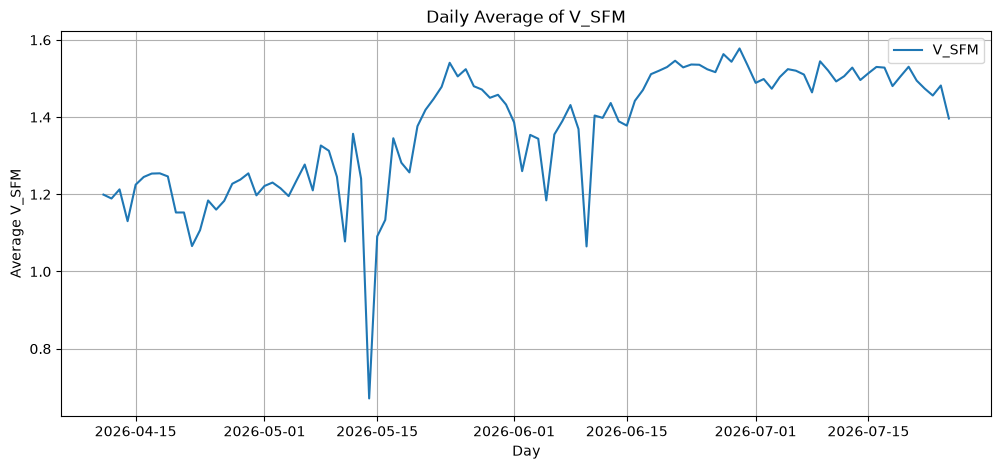

In [8]:
# Average V_SFM for each day
df_daily = df.groupby("day", as_index=False)["V_SFM"].mean()

df_daily.plot(
    x="day",
    y="V_SFM",
    kind="line",
    figsize=(12, 5),
    title="Daily Average of V_SFM",
    xlabel="Day",
    ylabel="Average V_SFM",
    grid=True
)

plt.show()

We observe two main effects:
1. The value increases on average over the period.
2. There are peaks near the anomalies (meterological phenomena).

**Note :** Because the daily average is varying over time we cannot measure the daily variation respect to the global average but only respect to the daily average

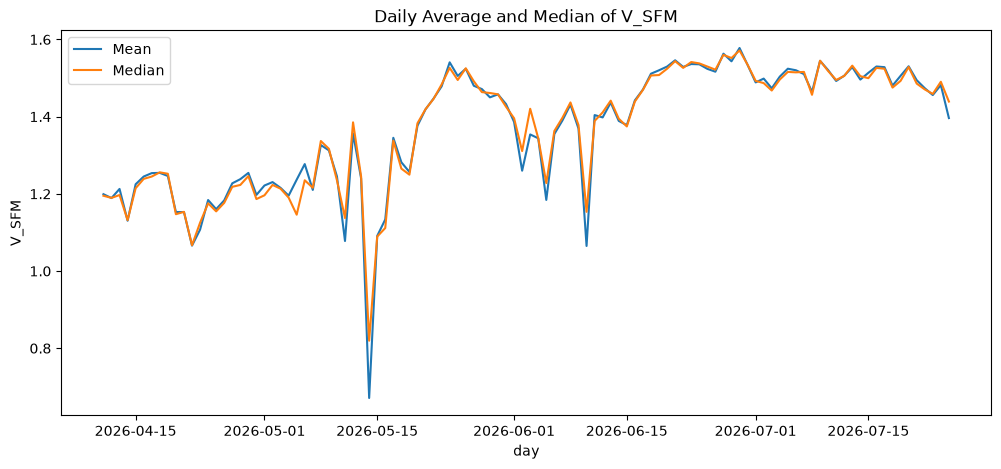

In [9]:
# Median V_SFM for each day
df_daily_median = df.groupby("day", as_index=False)["V_SFM"].median()

ax = df_daily.plot(
    x="day",
    y="V_SFM",
    kind="line",
    figsize=(12, 5),
    title="Daily Average and Median of V_SFM",
    xlabel="Day",
    ylabel="V_SFM",
    grid=True,
    label="Mean"
)

df_daily_median.plot(
    x="day",
    y="V_SFM",
    ax=ax,
    label="Median"
)

ax.legend()
plt.show()

**Note 2 :** Because the daily average is highly dependent on the anomalies we can take as reference the daily median wich is less dependent on hourly anomalies

## 3- Calculating the average daily variation

`V_SFM_daily_variation` is defined as the difference between `V_SFM` and its daily median

In [10]:
# V_SFM_daily_variation as the diff between V_SFM and its daily median
df = df.merge(df_daily, on="day", suffixes=("", "_daily_avg"))
df = df.merge(df_daily_median, on="day", suffixes=("", "_daily_median"))

df["V_SFM_daily_variation"] = df["V_SFM"] - df["V_SFM_daily_median"]

df

,ID,DateTime,Vbatt,T_SHT,H_SHT,T_BMP,P_BMP,Q_SFM,V_SFM,T_SFM,day,hour,hour_15min_interval,V_SFM_daily_avg,V_SFM_daily_median,V_SFM_daily_variation
0,1,2026-04-11 15:30:00,4.18,5.675,74.6,5.33,920.25,5.891667,1.188908,5.425,2026-04-11,15:30,15:30,1.199125,1.195022,-0.006114
1,2,2026-04-11 15:45:00,4.18,5.520,71.5,5.09,920.27,5.791666,1.174219,5.465,2026-04-11,15:45,15:45,1.199125,1.195022,-0.020803
2,3,2026-04-11 16:00:00,4.18,5.408,67.9,5.02,920.26,5.391667,1.115192,5.485,2026-04-11,16:00,16:00,1.199125,1.195022,-0.079830
3,4,2026-04-11 16:15:00,4.18,5.464,65.0,4.98,920.30,5.258333,1.095403,5.405,2026-04-11,16:15,16:15,1.199125,1.195022,-0.099619
4,5,2026-04-11 16:30:00,4.18,5.338,64.2,4.98,920.44,6.883333,1.332115,5.390,2026-04-11,16:30,16:30,1.199125,1.195022,0.137093
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10149,10150,2026-07-25 10:38:00,3.44,5.256,94.6,4.92,923.86,7.416666,1.407509,5.200,2026-07-25,10:38,10:30,1.396299,1.439085,-0.031576
10150,10151,2026-07-25 10:54:00,3.44,5.312,94.7,4.91,923.85,7.783333,1.458913,5.135,2026-07-25,10:54,10:45,1.396299,1.439085,0.019828
10151,10152,2026-07-25 11:08:00,3.44,5.352,94.7,4.92,923.84,7.625000,1.436750,5.130,2026-07-25,11:08,11:00,1.396299,1.439085,-0.002335
10152,10153,2026-07-25 11:23:00,3.44,5.312,94.6,4.91,923.85,0.075000,0.069239,5.305,2026-07-25,11:23,11:15,1.396299,1.439085,-1.369846


#### Obvervation of random days

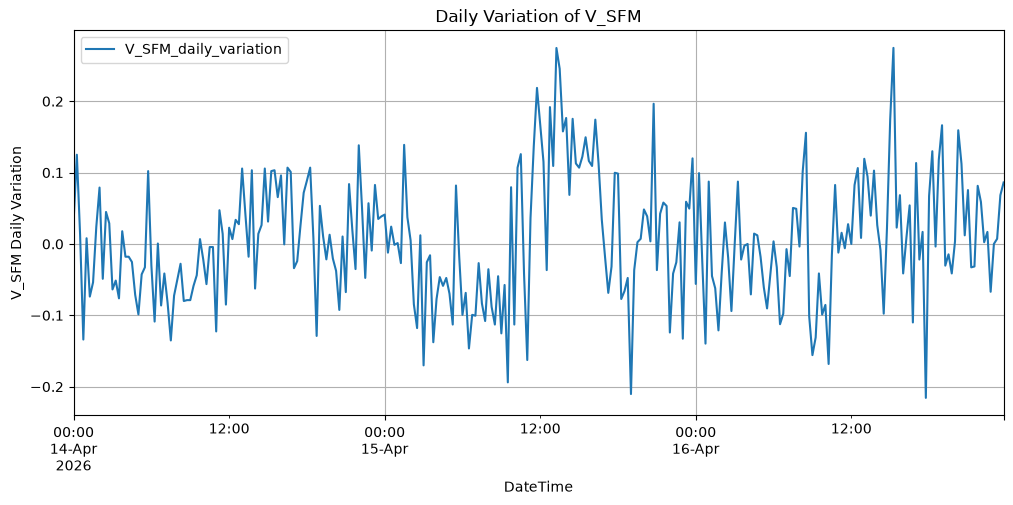

In [11]:
# Plot the daily variation of V_SFM for 3 specific consecutive days between 2026-04-11 and 2026-07-25
specific_days = ["2026-04-14", "2026-04-15", "2026-04-16"]
df_specific_days = df[df["day"].astype(str).isin(specific_days)]
df_specific_days.plot(
    x="DateTime",
    y="V_SFM_daily_variation",
    kind="line",
    figsize=(12, 5),
    title="Daily Variation of V_SFM",
    xlabel="DateTime",
    ylabel="V_SFM Daily Variation",
    grid=True
)
plt.show()

## 4- Calculating the average daily variation

For each hour (or 15 minutes cut), we calculate the average of the daily variation at this hour accross all the sampling period.

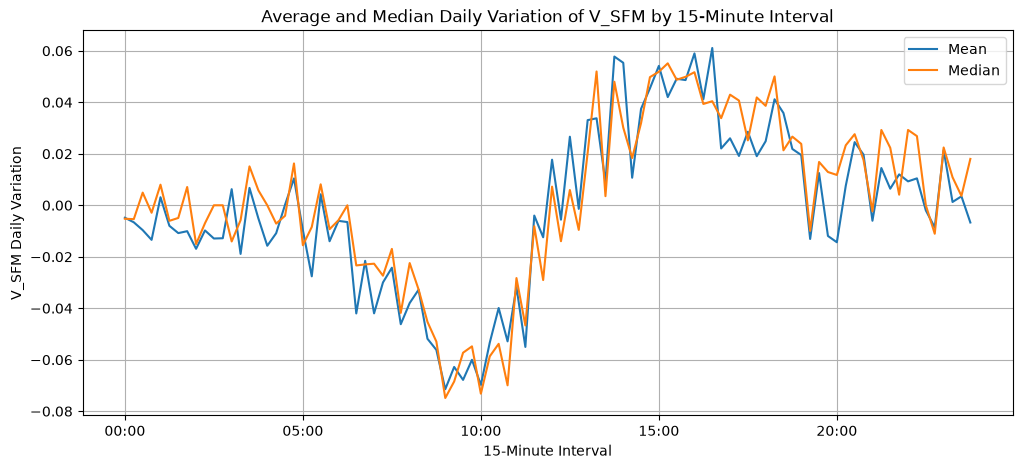

In [12]:
# Calculating the average and median daily variation of V_SFM for each 15-minute interval
df_avg_dailyvar = (
    df.groupby("hour_15min_interval")["V_SFM_daily_variation"]
      .agg(
          V_SFM_daily_variation="mean",
          V_SFM_median_daily_variation="median"
      )
      .reset_index()
)

# Plot the average and median daily variation of V_SFM for each 15-minute interval
df_avg_dailyvar.plot(
    x="hour_15min_interval",
    y=["V_SFM_daily_variation", "V_SFM_median_daily_variation"],
    kind="line",
    figsize=(12, 5),
    title="Average and Median Daily Variation of V_SFM by 15-Minute Interval",
    xlabel="15-Minute Interval",
    ylabel="V_SFM Daily Variation",
    grid=True,
    label=["Mean", "Median"]
)

plt.show()

Here we can compare the average and median daily variation of `V_SFM`, once again using the median allow us to be less dependent form the anomaly day. However because anomalies are a minority in the whole data we can observe that both the indicators are near to each other.

### Cleaning the average daily variation

We can observe in the data small variation of a scale smaller that 15 min (the sampling period). We cannot analyse those variation because their frequence is too high. In order to avoid this noise to have too much impact on the data we chose to perform a rolling mean of one hour for each 15 min point.

**Note :** One could chose to perform the rolling mean even before the whole analysis (section 1 for example)

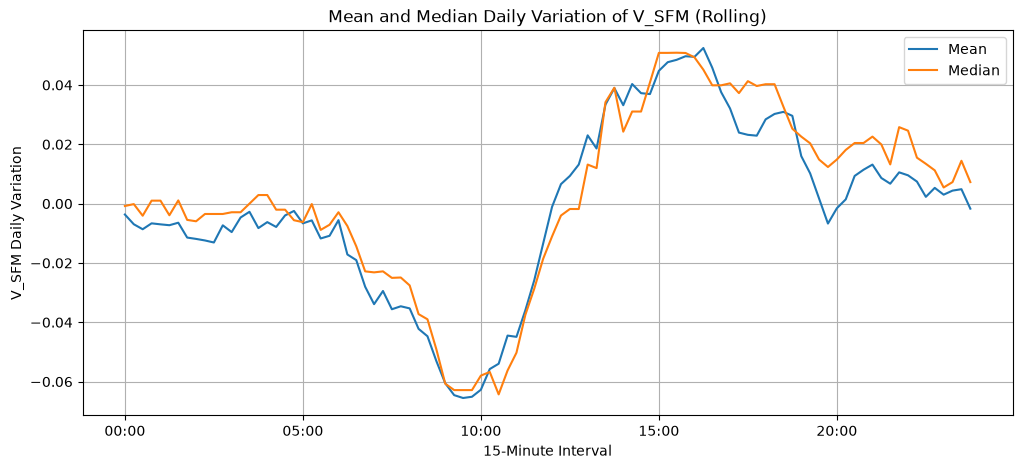

In [13]:
# Flatten the mean and median curves using a rolling window of 4 intervals (1 hour), consider that the data is periodic so we can use the end of the series to fill the beginning and the end of the rolling window
# Use periodic padding so the rolling window wraps around midnight
window = 4
padding = window // 2

periodic_values = pd.concat(
    [
        df_avg_dailyvar.iloc[-padding:],
        df_avg_dailyvar,
        df_avg_dailyvar.iloc[:padding+1]
    ],
    ignore_index=True
)

df_avg_dailyvar["V_SFM_daily_variation_rolling"] = (
    periodic_values["V_SFM_daily_variation"]
    .rolling(window=window, center=True)
    .mean()
    .iloc[padding:padding + len(df_avg_dailyvar)]
    .to_numpy()
)

df_avg_dailyvar["V_SFM_median_daily_variation_rolling"] = (
    periodic_values["V_SFM_median_daily_variation"]
    .rolling(window=window, center=True)
    .median()
    .iloc[padding:padding + len(df_avg_dailyvar)]
    .to_numpy()
)

# Plot both rolling curves
df_avg_dailyvar.plot(
    x="hour_15min_interval",
    y=[
        "V_SFM_daily_variation_rolling",
        "V_SFM_median_daily_variation_rolling"
    ],
    figsize=(12, 5),
    title="Mean and Median Daily Variation of V_SFM (Rolling)",
    xlabel="15-Minute Interval",
    ylabel="V_SFM Daily Variation",
    grid=True,
    label=["Mean", "Median"]
)

plt.show()

The result are coherent from what exected, with regular daily variations depending on the outside temperatures

## 5- Removing daily variation from the dataset

In [14]:
df

,ID,DateTime,Vbatt,T_SHT,H_SHT,T_BMP,P_BMP,Q_SFM,V_SFM,T_SFM,day,hour,hour_15min_interval,V_SFM_daily_avg,V_SFM_daily_median,V_SFM_daily_variation
0,1,2026-04-11 15:30:00,4.18,5.675,74.6,5.33,920.25,5.891667,1.188908,5.425,2026-04-11,15:30,15:30,1.199125,1.195022,-0.006114
1,2,2026-04-11 15:45:00,4.18,5.520,71.5,5.09,920.27,5.791666,1.174219,5.465,2026-04-11,15:45,15:45,1.199125,1.195022,-0.020803
2,3,2026-04-11 16:00:00,4.18,5.408,67.9,5.02,920.26,5.391667,1.115192,5.485,2026-04-11,16:00,16:00,1.199125,1.195022,-0.079830
3,4,2026-04-11 16:15:00,4.18,5.464,65.0,4.98,920.30,5.258333,1.095403,5.405,2026-04-11,16:15,16:15,1.199125,1.195022,-0.099619
4,5,2026-04-11 16:30:00,4.18,5.338,64.2,4.98,920.44,6.883333,1.332115,5.390,2026-04-11,16:30,16:30,1.199125,1.195022,0.137093
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10149,10150,2026-07-25 10:38:00,3.44,5.256,94.6,4.92,923.86,7.416666,1.407509,5.200,2026-07-25,10:38,10:30,1.396299,1.439085,-0.031576
10150,10151,2026-07-25 10:54:00,3.44,5.312,94.7,4.91,923.85,7.783333,1.458913,5.135,2026-07-25,10:54,10:45,1.396299,1.439085,0.019828
10151,10152,2026-07-25 11:08:00,3.44,5.352,94.7,4.92,923.84,7.625000,1.436750,5.130,2026-07-25,11:08,11:00,1.396299,1.439085,-0.002335
10152,10153,2026-07-25 11:23:00,3.44,5.312,94.6,4.91,923.85,0.075000,0.069239,5.305,2026-07-25,11:23,11:15,1.396299,1.439085,-1.369846


In [15]:
# Map the median daily variation to each V_SFM measurement
median_daily_variation_by_time = df_avg_dailyvar.set_index(
    "hour_15min_interval"
)["V_SFM_median_daily_variation"]

df["V_SFM_without_median_daily_variation"] = (
    df["V_SFM"]
    - df["hour_15min_interval"].map(median_daily_variation_by_time)
)

df[[
    "DateTime",
    "V_SFM",
    "hour_15min_interval",
    "V_SFM_without_median_daily_variation"
]]

,DateTime,V_SFM,hour_15min_interval,V_SFM_without_median_daily_variation
0,2026-04-11 15:30:00,1.188908,15:30,1.140141
1,2026-04-11 15:45:00,1.174219,15:45,1.124327
2,2026-04-11 16:00:00,1.115192,16:00,1.063506
3,2026-04-11 16:15:00,1.095403,16:15,1.056046
4,2026-04-11 16:30:00,1.332115,16:30,1.291692
...,...,...,...,...
10149,2026-07-25 10:38:00,1.407509,10:30,1.461322
10150,2026-07-25 10:54:00,1.458913,10:45,1.528836
10151,2026-07-25 11:08:00,1.436750,11:00,1.465023
10152,2026-07-25 11:23:00,0.069239,11:15,0.115914


## 6- Cleaning the result

Plot the same 3 radom days for comparison

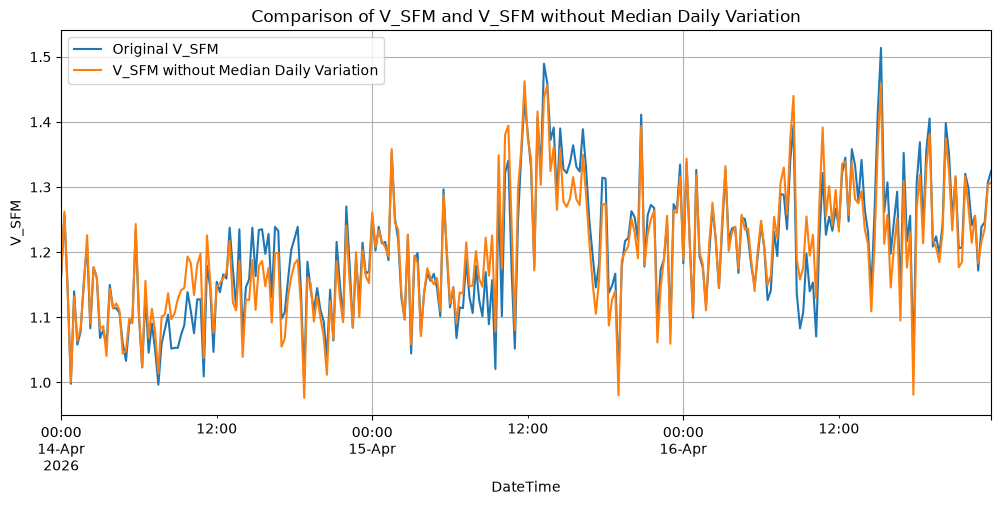

In [16]:
df_specific_days = df[df["day"].astype(str).isin(specific_days)]

# compare the original V_SFM and the V_SFM without median daily variation for the specific days
df_specific_days.plot(
    x="DateTime",
    y=["V_SFM", "V_SFM_without_median_daily_variation"],
    kind="line",
    figsize=(12, 5),
    title="Comparison of V_SFM and V_SFM without Median Daily Variation",
    xlabel="DateTime",
    ylabel="V_SFM",
    grid=True,
    label=["Original V_SFM", "V_SFM without Median Daily Variation"]
)

plt.show()

## 7- Saving the results

In [17]:
# Saving in a new CSV file
df.to_csv("data/data2_dates_corrigees_without_daily_variation.csv", index=False, encoding="utf-8-sig")

#### Documentation of the output

- `day` : day of the sample
- `hour` : hour of the sample
- `hour_15min_interval` : measurement time rounded down to the nearest 15-minute interval
- `V_SFM_daily_avg` : daily average of `V_SFM`
- `V_SFM_daily_median` : daily median of `V_SFM`
- `V_SFM_daily_variation` : difference between `V_SFM` and its daily median
- `V_SFM_without_median_daily_variation` : `V_SFM` after removing the median daily variation (flattened by hour average see section 5)

In [18]:
df

,ID,DateTime,Vbatt,T_SHT,H_SHT,T_BMP,P_BMP,Q_SFM,V_SFM,T_SFM,day,hour,hour_15min_interval,V_SFM_daily_avg,V_SFM_daily_median,V_SFM_daily_variation,V_SFM_without_median_daily_variation
0,1,2026-04-11 15:30:00,4.18,5.675,74.6,5.33,920.25,5.891667,1.188908,5.425,2026-04-11,15:30,15:30,1.199125,1.195022,-0.006114,1.140141
1,2,2026-04-11 15:45:00,4.18,5.520,71.5,5.09,920.27,5.791666,1.174219,5.465,2026-04-11,15:45,15:45,1.199125,1.195022,-0.020803,1.124327
2,3,2026-04-11 16:00:00,4.18,5.408,67.9,5.02,920.26,5.391667,1.115192,5.485,2026-04-11,16:00,16:00,1.199125,1.195022,-0.079830,1.063506
3,4,2026-04-11 16:15:00,4.18,5.464,65.0,4.98,920.30,5.258333,1.095403,5.405,2026-04-11,16:15,16:15,1.199125,1.195022,-0.099619,1.056046
4,5,2026-04-11 16:30:00,4.18,5.338,64.2,4.98,920.44,6.883333,1.332115,5.390,2026-04-11,16:30,16:30,1.199125,1.195022,0.137093,1.291692
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10149,10150,2026-07-25 10:38:00,3.44,5.256,94.6,4.92,923.86,7.416666,1.407509,5.200,2026-07-25,10:38,10:30,1.396299,1.439085,-0.031576,1.461322
10150,10151,2026-07-25 10:54:00,3.44,5.312,94.7,4.91,923.85,7.783333,1.458913,5.135,2026-07-25,10:54,10:45,1.396299,1.439085,0.019828,1.528836
10151,10152,2026-07-25 11:08:00,3.44,5.352,94.7,4.92,923.84,7.625000,1.436750,5.130,2026-07-25,11:08,11:00,1.396299,1.439085,-0.002335,1.465023
10152,10153,2026-07-25 11:23:00,3.44,5.312,94.6,4.91,923.85,0.075000,0.069239,5.305,2026-07-25,11:23,11:15,1.396299,1.439085,-1.369846,0.115914
